In [1]:
from google.colab import files
uploaded = files.upload()

Saving advanced_lithium_5yr_dataset.csv to advanced_lithium_5yr_dataset.csv


In [3]:

import math
import pandas as pd

df = pd.read_csv('/content/advanced_lithium_5yr_dataset.csv')

print(df.head())
print(df.columns.tolist())

def correlation(x, y):
    n = len(x)

    sum_x = sum(x)
    sum_y = sum(y)
    sum_xy = sum(x[i] * y[i] for i in range(n))
    sum_x2 = sum(i**2 for i in x)
    sum_y2 = sum(i**2 for i in y)

    numerator = n * sum_xy - sum_x * sum_y
    denominator = math.sqrt((n * sum_x2 - sum_x**2) *
                            (n * sum_y2 - sum_y**2))

    if denominator == 0:
        return None

    return numerator / denominator


     timestamp  ambient_temp_C  battery_temp_C  current_A  voltage_V  \
0     01-01-21       20.993428       20.668679  -3.507247   3.771202   
1  1/1/21 0:01       19.723710       21.165320  -0.848706   3.641096   
2  1/1/21 0:02       21.295855       21.842970   2.163465   3.489040   
3  1/1/21 0:03       23.046777       22.621924  -0.564716   3.623761   
4  1/1/21 0:04       19.532650       21.565621  -5.837468   3.905624   

       soc_%       soh_%  capacity_Ah  internal_resistance_ohm  cycle_count  \
0  50.000000  100.000000     2.500000                     0.05     0.000000   
1  50.565804   99.999883     2.499997                     0.05     0.005658   
2  49.123494   99.999591     2.499990                     0.05     0.020081   
3  49.499971   99.999512     2.499988                     0.05     0.023846   
4  53.391616   99.998730     2.499968                     0.05     0.062762   

   ...  voltage_roll_std  current_roll_mean  current_roll_std  temp_roll_mean  \
0  ...     

In [5]:

import matplotlib.pyplot as plt

def scatter_plot(x, y, title):
    plt.scatter(x, y, color="blue", alpha=0.5)
    plt.title(title)
    plt.xlabel("X Values")
    plt.ylabel("Y Values")
    plt.grid(True)
    plt.show()


Actual Dataset Correlation: 0.8516087826836641


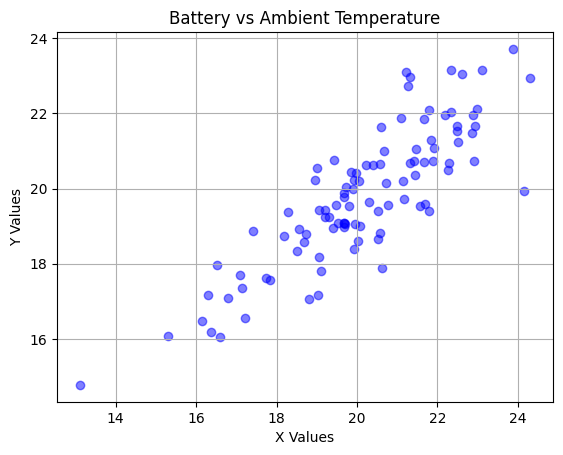

Negative Correlation: -1.0


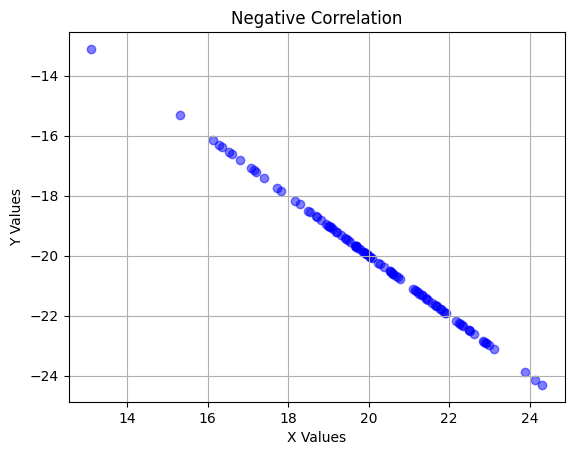

No Correlation: 4.735215165304962e-17


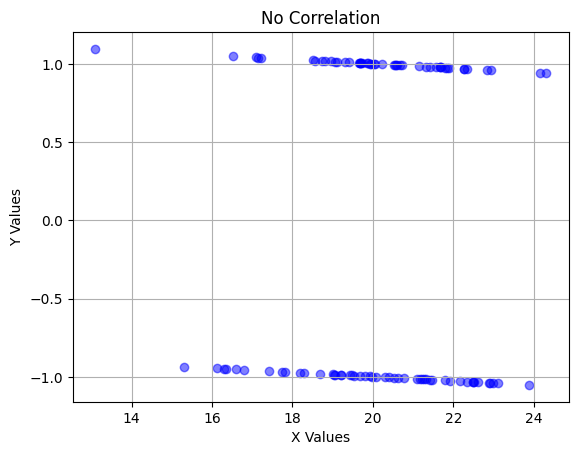

In [6]:

# Select numerical columns from dataset
columns = ["battery_temp_C", "ambient_temp_C"]
data = df[columns].dropna().head(100)

x = data["battery_temp_C"].tolist()
y = data["ambient_temp_C"].tolist()

# Actual Dataset Correlation
r = correlation(x, y)
print("Actual Dataset Correlation:", r)
scatter_plot(x, y, "Battery vs Ambient Temperature")

# Negative Correlation Example
y_negative = [-value for value in x]
print("Negative Correlation:", correlation(x, y_negative))
scatter_plot(x, y_negative, "Negative Correlation")

# No Correlation Example
# Alternating values are adjusted to give zero covariance
mean_x = sum(x) / len(x)
y_none = [1 if i % 2 == 0 else -1 for i in range(len(x))]
mean_y = sum(y_none) / len(y_none)

cov = sum((x[i]-mean_x)*(y_none[i]-mean_y)
          for i in range(len(x)))
var_x = sum((value-mean_x)**2 for value in x)

if var_x > 0:
    y_none = [y_none[i] - cov/var_x*(x[i]-mean_x)
              for i in range(len(x))]

print("No Correlation:", correlation(x, y_none))
scatter_plot(x, y_none, "No Correlation")
